In [10]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import sys
sys.path.append('../../../python_modules/')
# plt.rcdefaults() 
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

from domino.models.domino_models import DominoSingleOutput
from domino.utils import tools
from domino.data.domino_data import GenomeDataset
# import pytorch_lightning as pl
from domino.data.data import preprocess_data, process_bed_file_df
from domino.utils.tools import seq_from_df
import matplotlib.ticker as mticker
from generic_plotting_functions import *

import scipy.stats as stats
import pandas as pd
import os
import numpy as np

import fanc
import fanc.plotting as fancplot

from domino.utils.plotting import plot_attribution
from tqdm import tqdm
import coolbox
from coolbox.api import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load in predictions

In [4]:
model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

ws = 1
mean_scaling_window=10


nc14_rep_1_ins_path = f'/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/new_nc14_embryo_merged_all_11.resolution=200bp.insulation_{ws}kb.bed'
nc14_ins_1 = process_bed_file_df(nc14_rep_1_ins_path, 'ins_score')
nc14_ins_1["demeaned_ins_score"] = nc14_ins_1["ins_score"] - nc14_ins_1["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()

nc14_rep_2_ins_path = f'/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/nc14_embryo_merged_form_fed_8.resolution=200bp.insulation_{ws}kb.bed'
nc14_ins_2 = process_bed_file_df(nc14_rep_2_ins_path, 'ins_score')
nc14_ins_2["demeaned_ins_score"] = nc14_ins_2["ins_score"] - nc14_ins_2["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()

In [15]:
def get_demeaned_ins_track(row, ins, ins_score_context_bin_width=15000//200):
    chrom, start, end = row.chrom, row.start, row.end
    # get insulation around boundary of interest
    tmp = ins.query('chrom == @chrom and start == @start and end==@end')
    i = tmp.index.item()
    idxs_pos = np.arange(i-ins_score_context_bin_width, i+ins_score_context_bin_width+1)
    y_pos = np.array([np.array(ins['demeaned_ins_score'][idx_arr]) for idx_arr in idxs_pos]) # context with middle bin
    return y_pos
    
def get_track_correlations_pred(pred_arr, boundaries):
    pearson_correlations = []
    spearman_correlations = []
    
    for i, row in tqdm(boundaries.iterrows(), total=len(boundaries), desc="Processing rows"):
        # row = examples_to_test.iloc[100]
        y1 = get_demeaned_ins_track(row, nc14_ins_1)
        
        pred = pred_arr[i]
    
        pcc, scc, _ = masked_correlation_1d(y1, pred)
    
        pearson_correlations.append(pcc)
        spearman_correlations.append(scc)

    return pearson_correlations, spearman_correlations

import numpy as np
from scipy.ndimage import binary_dilation
from scipy.stats import pearsonr, spearmanr

def masked_correlation_1d(a, b, w=2):
    if len(a) != len(b):
        raise ValueError("Arrays must have same length")

    # Non-finite in either array
    bad = ~(np.isfinite(a) & np.isfinite(b))

    # Expand by w positions on each side
    structure = np.ones(2*w + 1, dtype=bool)
    bad_expanded = binary_dilation(bad, structure=structure)

    keep = ~bad_expanded

    x = a[keep]
    y = b[keep]

    if len(x) < 10 or len(y) < 10:
        return None, None, keep

    return (
        pearsonr(x, y).statistic,
        spearmanr(x, y).statistic,
        keep,
    )

In [16]:
nc14_bound_df = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/final_nc14_boundaries_df.bound_score_gt_1.csv')
nc14_bound_df = nc14_bound_df.query('has_stripe_at_bound == False')
nc14_bound_df = nc14_bound_df.drop_duplicates(['chrom', 'start', 'end'])

examples_to_test = TEST_df.merge(nc14_bound_df[['chrom', 'start', 'end']], on=['chrom', 'start', 'end']).drop_duplicates(['chrom', 'start', 'end'])
test_boundaries = examples_to_test.reset_index(drop=True)


In [17]:
test_predicted_arr = np.load('../supp_fig1/nc14_test_regions_predictions.npy')
_, test_spearmans = get_track_correlations_pred(test_predicted_arr, test_boundaries)
test_boundaries['pred_spearman'] = test_spearmans

from tqdm import tqdm 

rep_ins_spearman_correlations = []

for i, row in tqdm(test_boundaries.iterrows(), total=len(test_boundaries), desc="Processing rows"):
    y1 = get_demeaned_ins_track(row, nc14_ins_1)
    y2 = get_demeaned_ins_track(row, nc14_ins_2)
    pcc, scc, _ = masked_correlation_1d(y1, y2)
    rep_ins_spearman_correlations.append(scc)

test_boundaries['rep_spearman'] = rep_ins_spearman_correlations

Processing rows: 100%|██████████| 685/685 [00:25<00:00, 26.56it/s]


In [21]:
B = nc14_bound_df.copy()
# Sequence-dependent (MD)
A = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_rerun/fig5_clustermap/finalized_nc14_cluster_metadata.csv', index_col=0)

cols = ["chrom", "start", "end"]
merged = B.merge(A[cols], on=cols, how="left", indicator=True)

B_overlap = merged.loc[merged["_merge"] == "both"].drop(columns="_merge")
B_not_overlap = merged.loc[merged["_merge"] == "left_only"].drop(columns="_merge")

B_overlap_test = TEST_df.drop_duplicates(cols)[cols].merge(B_overlap, on=cols).drop_duplicates(cols)
B_not_overlap_test = TEST_df.drop_duplicates(cols)[cols].merge(B_not_overlap, on=cols).drop_duplicates(cols)

test_boundaries['coords'] = test_boundaries.chrom + ':' + test_boundaries.start.astype(str) + '-' + test_boundaries.end.astype(str)
B_overlap_test['coords'] = B_overlap_test.chrom + ':' + B_overlap_test.start.astype(str) + '-' + B_overlap_test.end.astype(str)
B_not_overlap_test['coords'] = B_not_overlap_test.chrom + ':' + B_not_overlap_test.start.astype(str) + '-' + B_not_overlap_test.end.astype(str)

In [24]:
n_sd = len(B_overlap_test.drop_duplicates(cols))
n_other = len(B_not_overlap_test.drop_duplicates(cols))
counts = test_boundaries.apply(lambda row: f"MD" if row['coords'] in B_overlap_test['coords'].tolist() else f"Other", axis=1).value_counts()
test_boundaries['category'] = test_boundaries.apply(lambda row: f"MD (n={counts['MD']})" if row['coords'] in B_overlap_test['coords'].tolist() else f"Other (n={counts['Other']})", axis=1)

In [25]:
test_boundaries.category.value_counts()

category
MD (n=398)       398
Other (n=287)    287
Name: count, dtype: int64

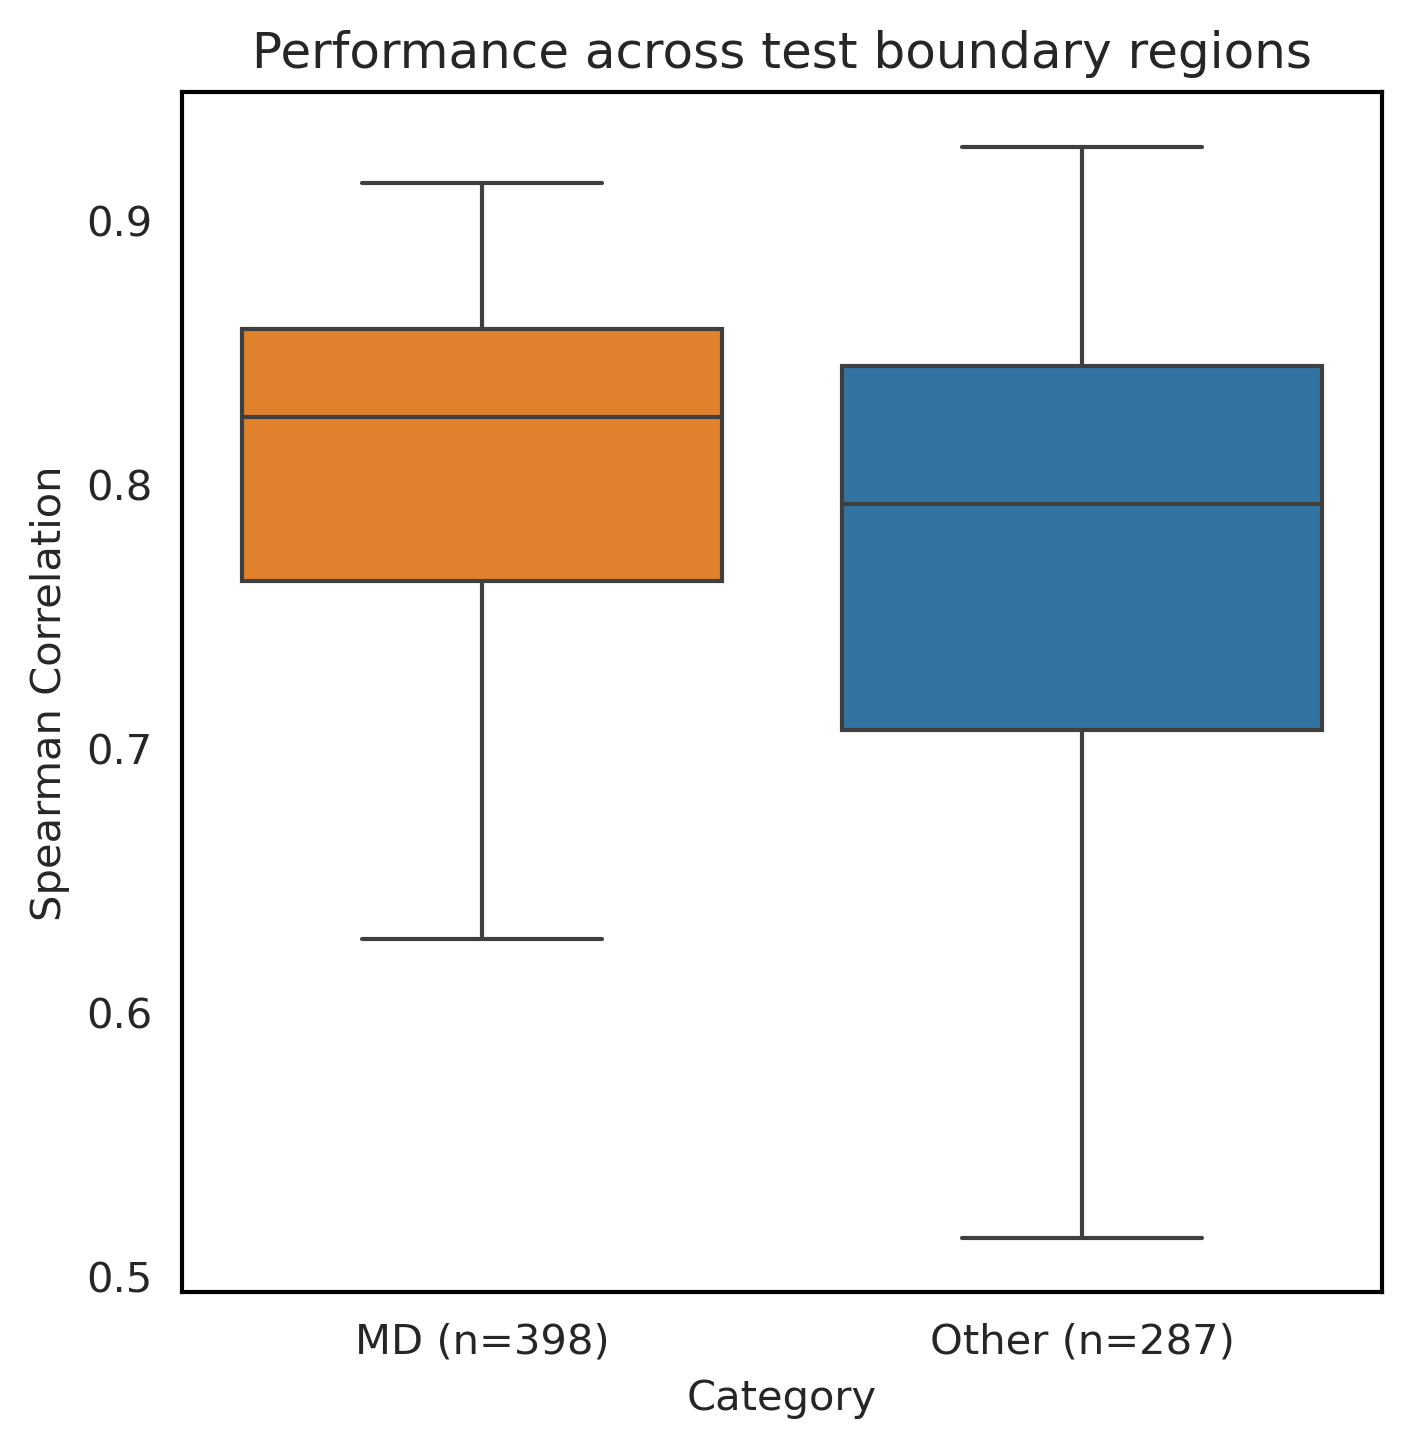

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


fig, ax = init_subplots_exact(1,1, x_ratios=[1], y_ratios=[1], dpi=300)


sns.boxplot(
    data=test_boundaries,
    x='category',
    y='pred_spearman',
    hue='category',
    order=['MD (n=398)', 'Other (n=287)'],
    ax=ax,
    showfliers=False
    # fliersize=1
)

ax.grid(False)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1)

plt.ylabel('Spearman Correlation')
plt.xlabel('Category')
plt.title('Performance across test boundary regions')
plt.show()

# Insulation here

In [30]:
seq_dep_boundaries = B_overlap.drop_duplicates(['chrom', 'start', 'end'])
other_boundaries = B_not_overlap.drop_duplicates(['chrom', 'start', 'end'])

non_boundary_examples = pd.concat([TRAIN_df, VAL_df, TEST_df]).reset_index(drop=True).query('boundary == 0').sample(n=len(seq_dep_boundaries), random_state=10)

In [33]:
def top_whisker(values):
    q1 = np.percentile(values, 25)
    q3 = np.percentile(values, 75)
    iqr = q3 - q1
    upper_fence = q3 + 1.5 * iqr
    return upper_fence


MD Other
3426570.0 4.0318001975062926e-259
MD Control
255860.0 0.0
Other Control
725331.0 0.0
MD Other 4.0318001975062926e-259
MD Control 0.0
Other Control 0.0


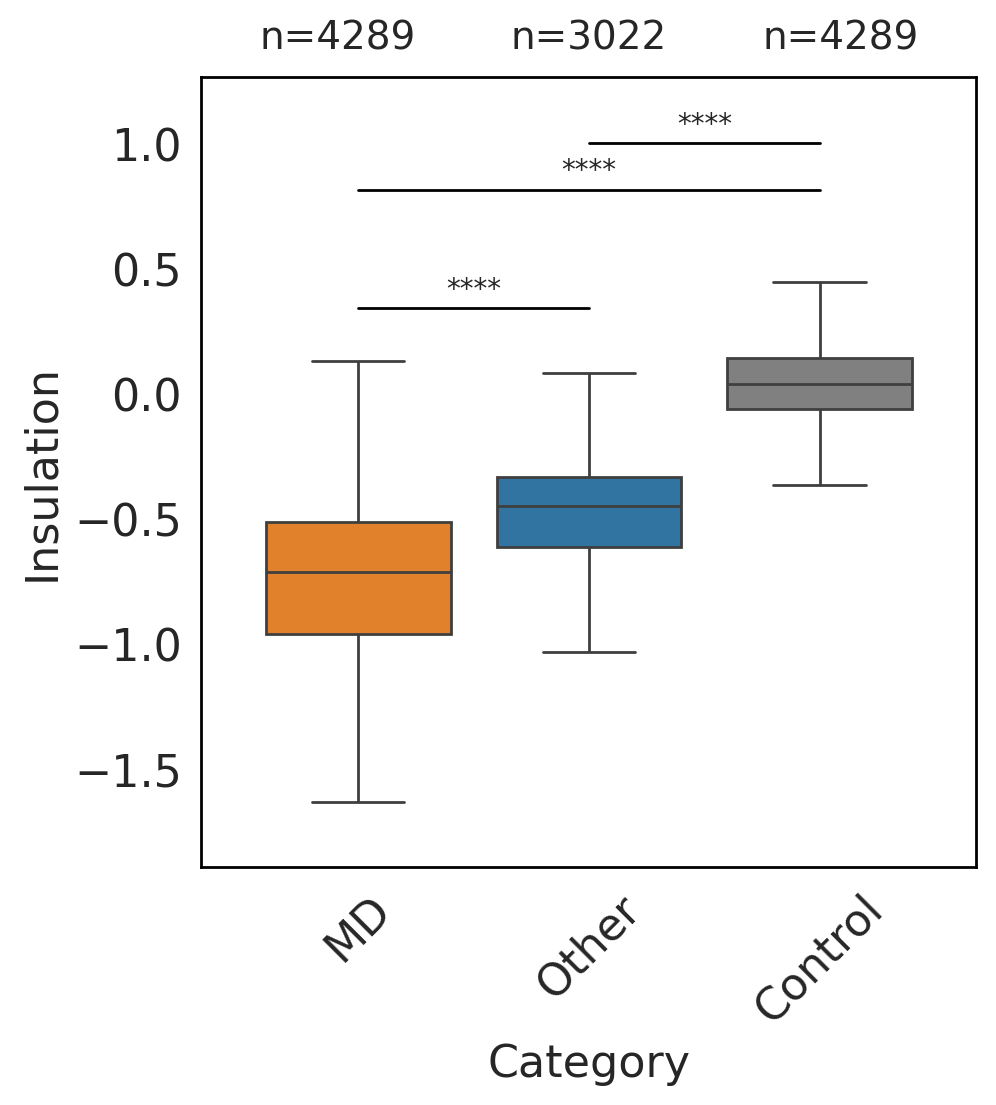

In [34]:
import numpy as np
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import itertools


group_1 = seq_dep_boundaries['demeaned_ins_score_1'].to_numpy()
group_2 = other_boundaries['demeaned_ins_score_1'].to_numpy()
group_3 = non_boundary_examples['demeaned_ins_score_1'].to_numpy()

df = pd.DataFrame({
    'value': np.concatenate([group_1, group_2, group_3]),
    'group': (['MD'] * len(group_1) + ['Other'] * len(group_2) +
              ['Control'] * len(group_3))
})

medians = df.groupby('group')['value'].median().sort_values(ascending=True)
group_order = medians.index.tolist()
# target = group_order[-1]
# pairs = [(g, target) for g in group_order[3:-1] if g != target]
pairs = list(itertools.combinations(group_order, 2))

# Plot
old_rc = plt.rcParams.copy()
plt.rcParams['font.size'] = 16

fig, ax = plt.subplots(figsize=(5,5))
bax = sns.boxplot(data=df, x='group', y='value', order=group_order, palette=['C1', 'C0', 'gray'], showfliers=False, ax=ax)

whiskers = {
    g: top_whisker(df[df['group'] == g]['value']) for g in group_order
}

p_values = []
for g1, g2 in pairs:
    print(g1, g2)
    vals1 = df[df['group'] == g1]['value']
    vals2 = df[df['group'] == g2]['value']
    stat, pval = mannwhitneyu(vals1, vals2, alternative='less')
    print(stat, pval)
    p_values.append(pval)

reject, pvals_corrected, _, _ = multipletests(p_values, alpha=0.05, method='fdr_bh')

spacing = 0.185
sig_index = 0  # separate counter for non-significant pairs
for (g1, g2), pval_corr, sig in zip(pairs, pvals_corrected, reject):
    if sig:  # only non-significant
        print(g1, g2, pval_corr)
        x1, x2 = group_order.index(g1), group_order.index(g2)
        y = max(whiskers[g1], whiskers[g2]) + spacing * (sig_index + 1)
        
        ax.plot([x1, x2], [y, y], lw=1, color='black')
        ax.text((x1 + x2)/2, y + 0.02, "****", ha='center', va='bottom', fontsize=10)
        
        sig_index += 1  # increment only for non-significant pairs


plt.xticks(rotation=45)
ax.margins(x=0.1, y=0.1)  # 10% padding on both axes

group_counts = df["group"].value_counts()[group_order]
for i, count in enumerate(group_counts):
    x_display = ax.get_xticks()[i]
    x_fig, _ = ax.transData.transform((x_display, 0))
    x_fig_rel = fig.transFigure.inverted().transform((x_fig, 0))[0]
    fig.text(x_fig_rel, 0.92, f"n={count}", 
             ha='center', va='bottom', fontsize=14)
plt.subplots_adjust(top=0.9)  # leave space at top

for spine in ax.spines.values():
    spine.set_linewidth(1)  
    spine.set_color('black')  

plt.xlabel('Category')
plt.ylabel('Insulation')
plt.grid(False)
plt.show()

plt.rcParams.update(old_rc)
